In [2]:
from pathlib import Path
import pandas as pd
import numpy as np

DATA_DIR = Path(r"D:\battery_soh\CALCE-CX2\CX2_data")

files = sorted(DATA_DIR.rglob("*.xlsx"))

print("Excel files:", len(files))
print("First file:", files[0] if files else "None")

Excel files: 419
First file: D:\battery_soh\CALCE-CX2\CX2_data\CX2_16\CX2_16_10_14_11.xlsx


In [3]:
from collections import Counter

battery_counts = Counter(
    next(
        (p for p in file.relative_to(DATA_DIR).parts
         if p.startswith("CX2_")),
        "Unknown"
    )
    for file in files
)

display(
    pd.DataFrame(
        battery_counts.items(),
        columns=["Battery", "Files"]
    ).sort_values("Battery")
)

,Battery,Files
0,CX2_16,52
1,CX2_3,63
2,CX2_32,10
3,CX2_33,45
4,CX2_34,43
5,CX2_35,48
6,CX2_36,48
7,CX2_37,31
8,CX2_38,47
9,CX2_8,32


In [4]:
file = files[0]

book = pd.ExcelFile(file)
sheet = next(s for s in book.sheet_names if s.startswith("Channel"))

df = pd.read_excel(book, sheet_name=sheet)
df.columns = df.columns.str.strip()

discharge = df[df["Current(A)"] < -0.01]

print("File:", file.name)
print("Discharge rows:", len(discharge))

display(discharge.head(10))

File: CX2_16_10_14_11.xlsx
Discharge rows: 11917


,Data_Point,Test_Time(s),Date_Time,Step_Time(s),Step_Index,Cycle_Index,Current(A),Voltage(V),Charge_Capacity(Ah),Discharge_Capacity(Ah),Charge_Energy(Wh),Discharge_Energy(Wh),dV/dt(V/s),Internal_Resistance(Ohm),Is_FC_Data,AC_Impedance(Ohm),ACI_Phase_Angle(Deg)
179,180,9528.625865,2011-10-04 16:13:42,0.000003,7,1,-0.549993,4.132677,1.063305,0.000003,4.301954,0.000012,0.000000,0.092455,0,0,0
180,181,9558.640845,2011-10-04 16:14:12,30.014983,7,1,-0.550173,4.101898,1.063305,0.004590,4.301954,0.018874,-0.000454,0.092455,0,0,0
181,182,9588.655701,2011-10-04 16:14:42,60.029839,7,1,-0.550173,4.089262,1.063305,0.009177,4.301954,0.037659,-0.000324,0.092455,0,0,0
182,183,9618.670474,2011-10-04 16:15:12,90.044612,7,1,-0.550353,4.080029,1.063305,0.013764,4.301954,0.056395,-0.000227,0.092455,0,0,0
183,184,9648.685427,2011-10-04 16:15:42,120.059565,7,1,-0.549993,4.072902,1.063305,0.018351,4.301954,0.075093,-0.000097,0.092455,0,0,0
184,185,9678.700165,2011-10-04 16:16:12,150.074303,7,1,-0.550173,4.066260,1.063305,0.022939,4.301954,0.093759,-0.000162,0.092455,0,0,0
185,186,9708.715202,2011-10-04 16:16:42,180.089340,7,1,-0.550353,4.060428,1.063305,0.027526,4.301954,0.112398,-0.000162,0.092455,0,0,0
186,187,9738.730239,2011-10-04 16:17:12,210.104377,7,1,-0.550353,4.054759,1.063305,0.032113,4.301954,0.131011,-0.000194,0.092455,0,0,0
187,188,9768.744757,2011-10-04 16:17:42,240.118894,7,1,-0.550353,4.049575,1.063305,0.036700,4.301954,0.149599,-0.000130,0.092455,0,0,0
188,189,9798.759618,2011-10-04 16:18:12,270.133756,7,1,-0.550353,4.044391,1.063305,0.041287,4.301954,0.168164,-0.000194,0.092455,0,0,0


In [5]:
import pandas as pd
import numpy as np

df["Cycle_Index"] = pd.to_numeric(df["Cycle_Index"], errors="coerce")
df["Current(A)"] = pd.to_numeric(df["Current(A)"], errors="coerce")
df["Discharge_Capacity(Ah)"] = pd.to_numeric(
    df["Discharge_Capacity(Ah)"], errors="coerce"
)

discharge = df[df["Current(A)"] < -0.01].copy()

cycle_capacity = (
    discharge.groupby("Cycle_Index")
    .agg(
        discharge_capacity_ah=("Discharge_Capacity(Ah)", "max"),
        samples=("Current(A)", "size"),
        min_voltage=("Voltage(V)", "min"),
        max_voltage=("Voltage(V)", "max")
    )
    .reset_index()
)

cycle_capacity["soh_candidate"] = (
    cycle_capacity["discharge_capacity_ah"] / 1.35 * 100
)

display(cycle_capacity.head(15))

,Cycle_Index,discharge_capacity_ah,samples,min_voltage,max_voltage,soh_candidate
0,1,1.080768,237,2.699861,4.132677,80.056852
1,2,2.176763,240,2.699861,4.135916,161.241720
2,3,3.287538,244,2.699861,4.134134,243.521297
3,4,4.383007,240,2.699861,4.134459,324.667155
4,5,5.474661,239,2.699861,4.132029,405.530450
5,6,6.565862,239,2.699861,4.133486,486.360181
6,7,7.656877,239,2.699861,4.139156,567.176105
7,8,8.764421,243,2.699861,4.135107,649.216374
8,9,9.863823,241,2.699861,4.135268,730.653533
9,10,10.945952,237,2.699861,4.130085,810.811250


In [6]:
import pandas as pd
import numpy as np

df["Cycle_Index"] = pd.to_numeric(df["Cycle_Index"], errors="coerce")
df["Current(A)"] = pd.to_numeric(df["Current(A)"], errors="coerce")
df["Discharge_Capacity(Ah)"] = pd.to_numeric(
    df["Discharge_Capacity(Ah)"], errors="coerce"
)

discharge = df[df["Current(A)"] < -0.01].copy()

cycle_capacity = (
    discharge.groupby("Cycle_Index")
    .agg(
        discharge_capacity_ah=("Discharge_Capacity(Ah)", "max"),
        samples=("Current(A)", "size"),
        min_voltage=("Voltage(V)", "min"),
        max_voltage=("Voltage(V)", "max")
    )
    .reset_index()
)

cycle_capacity["soh_candidate"] = (
    cycle_capacity["discharge_capacity_ah"] / 1.35 * 100
)

display(cycle_capacity.head(15))

,Cycle_Index,discharge_capacity_ah,samples,min_voltage,max_voltage,soh_candidate
0,1,1.080768,237,2.699861,4.132677,80.056852
1,2,2.176763,240,2.699861,4.135916,161.241720
2,3,3.287538,244,2.699861,4.134134,243.521297
3,4,4.383007,240,2.699861,4.134459,324.667155
4,5,5.474661,239,2.699861,4.132029,405.530450
5,6,6.565862,239,2.699861,4.133486,486.360181
6,7,7.656877,239,2.699861,4.139156,567.176105
7,8,8.764421,243,2.699861,4.135107,649.216374
8,9,9.863823,241,2.699861,4.135268,730.653533
9,10,10.945952,237,2.699861,4.130085,810.811250


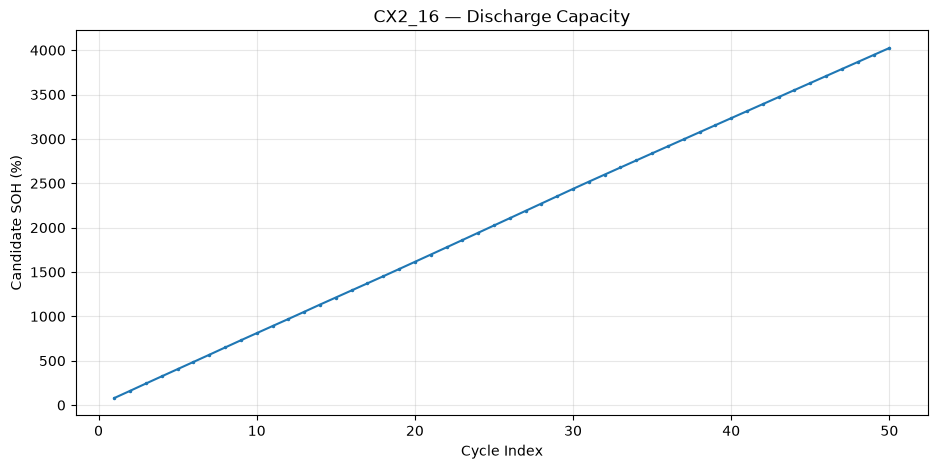

In [7]:
import matplotlib.pyplot as plt

plt.figure(figsize=(11, 5))

plt.plot(
    cycle_capacity["Cycle_Index"],
    cycle_capacity["soh_candidate"],
    marker=".",
    markersize=3
)

plt.xlabel("Cycle Index")
plt.ylabel("Candidate SOH (%)")
plt.title("CX2_16 — Discharge Capacity")
plt.grid(alpha=0.3)
plt.show()

In [8]:
print("Cycles found:", len(cycle_capacity))

print(
    cycle_capacity[
        ["discharge_capacity_ah", "soh_candidate", "samples"]
    ].describe()
)

print(
    "SOH above 110%:",
    (cycle_capacity["soh_candidate"] > 110).sum()
)

print(
    "SOH below 50%:",
    (cycle_capacity["soh_candidate"] < 50).sum()
)

Cycles found: 50
       discharge_capacity_ah  soh_candidate    samples
count              50.000000      50.000000   50.00000
mean               27.835740    2061.906703  238.34000
std                15.881037    1176.373078    3.63436
min                 1.080768      80.056852  234.00000
25%                14.466232    1071.572718  235.00000
50%                27.883591    2065.451187  237.00000
75%                41.250343    3055.580973  241.00000
max                54.332386    4024.621193  245.00000
SOH above 110%: 49
SOH below 50%: 0


In [9]:
print("Cycles found:", len(cycle_capacity))

print(
    cycle_capacity[
        ["discharge_capacity_ah", "soh_candidate", "samples"]
    ].describe()
)

print(
    "SOH above 110%:",
    (cycle_capacity["soh_candidate"] > 110).sum()
)

print(
    "SOH below 50%:",
    (cycle_capacity["soh_candidate"] < 50).sum()
)

Cycles found: 50
       discharge_capacity_ah  soh_candidate    samples
count              50.000000      50.000000   50.00000
mean               27.835740    2061.906703  238.34000
std                15.881037    1176.373078    3.63436
min                 1.080768      80.056852  234.00000
25%                14.466232    1071.572718  235.00000
50%                27.883591    2065.451187  237.00000
75%                41.250343    3055.580973  241.00000
max                54.332386    4024.621193  245.00000
SOH above 110%: 49
SOH below 50%: 0


In [10]:

# Calculate capacity delivered within each discharge cycle
discharge = df[df["Current(A)"] < -0.01].copy()

cycle_capacity = (
    discharge.groupby("Cycle_Index", sort=True)
    .agg(
        start_capacity=("Discharge_Capacity(Ah)", "first"),
        end_capacity=("Discharge_Capacity(Ah)", "last"),
        samples=("Current(A)", "size"),
        min_voltage=("Voltage(V)", "min")
    )
    .reset_index()
)

cycle_capacity["discharge_capacity_ah"] = (
    cycle_capacity["end_capacity"]
    - cycle_capacity["start_capacity"]
)

cycle_capacity["soh_candidate"] = (
    cycle_capacity["discharge_capacity_ah"] / 1.35 * 100
)

display(cycle_capacity.head(15))
print(cycle_capacity["soh_candidate"].describe())


,Cycle_Index,start_capacity,end_capacity,samples,min_voltage,discharge_capacity_ah,soh_candidate
0,1,0.000003,1.080768,237,2.699861,1.080765,80.056634
1,2,1.080774,2.176763,240,2.699861,1.095990,81.184423
2,3,2.176772,3.287538,244,2.699861,1.110766,82.278952
3,4,3.287546,4.383007,240,2.699861,1.095461,81.145238
4,5,4.383015,5.474661,239,2.699861,1.091646,80.862669
5,6,5.474669,6.565862,239,2.699861,1.091193,80.829108
6,7,6.565869,7.656877,239,2.699861,1.091009,80.815461
7,8,7.656884,8.764421,243,2.699861,1.107537,82.039807
8,9,8.764430,9.863823,241,2.699861,1.099393,81.436522
9,10,9.863831,10.945952,237,2.699861,1.082121,80.157086


count    50.000000
mean     80.491840
std       1.233473
min      78.932929
25%      79.386616
50%      80.007406
75%      81.499418
max      82.714493
Name: soh_candidate, dtype: float64


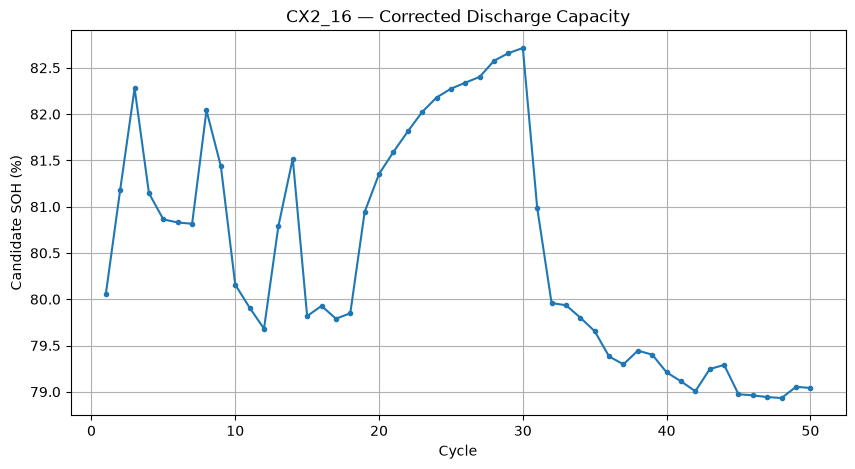

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))
plt.plot(
    cycle_capacity["Cycle_Index"],
    cycle_capacity["soh_candidate"],
    marker="o",
    markersize=3
)
plt.xlabel("Cycle")
plt.ylabel("Candidate SOH (%)")
plt.title("CX2_16 — Corrected Discharge Capacity")
plt.grid(True)
plt.show()

In [12]:
import numpy as np
import pandas as pd

rows = []

for cycle, group in df.groupby("Cycle_Index"):
    g = group.sort_values("Test_Time(s)").copy()

    t = g["Test_Time(s)"].to_numpy(dtype=float)
    i = g["Current(A)"].to_numpy(dtype=float)

    dt = np.diff(t)
    current = (i[:-1] + i[1:]) / 2

    valid = (dt > 0) & (dt < 600) & (current < -0.01)

    q_integrated = np.sum(
        -current[valid] * dt[valid] / 3600
    )

    rows.append({
        "cycle": cycle,
        "integrated_capacity_ah": q_integrated,
        "integrated_soh": q_integrated / 1.35 * 100
    })

validated = pd.DataFrame(rows)

display(validated.head(10))


,cycle,integrated_capacity_ah,integrated_soh
0,1,1.080798,80.059137
1,2,1.096013,81.186152
2,3,1.110782,82.280172
3,4,1.095467,81.145679
4,5,1.091672,80.864564
5,6,1.091210,80.830352
6,7,1.090999,80.814746
7,8,1.107566,82.041933
8,9,1.099431,81.439331
9,10,1.082151,80.159330


In [13]:
comparison = cycle_capacity.merge(
    validated,
    left_on="Cycle_Index",
    right_on="cycle"
)

comparison["difference_percent"] = abs(
    comparison["soh_candidate"] -
    comparison["integrated_soh"]
)

display(comparison[[
    "Cycle_Index",
    "soh_candidate",
    "integrated_soh",
    "difference_percent"
]].head(15))

print(
    "Mean absolute difference:",
    comparison["difference_percent"].mean(),
    "percentage points"
)

,Cycle_Index,soh_candidate,integrated_soh,difference_percent
0,1,80.056634,80.059137,0.002503
1,2,81.184423,81.186152,0.001730
2,3,82.278952,82.280172,0.001220
3,4,81.145238,81.145679,0.000441
4,5,80.862669,80.864564,0.001894
5,6,80.829108,80.830352,0.001243
6,7,80.815461,80.814746,0.000715
7,8,82.039807,82.041933,0.002126
8,9,81.436522,81.439331,0.002809
9,10,80.157086,80.159330,0.002243


Mean absolute difference: 0.0012956087206552524 percentage points


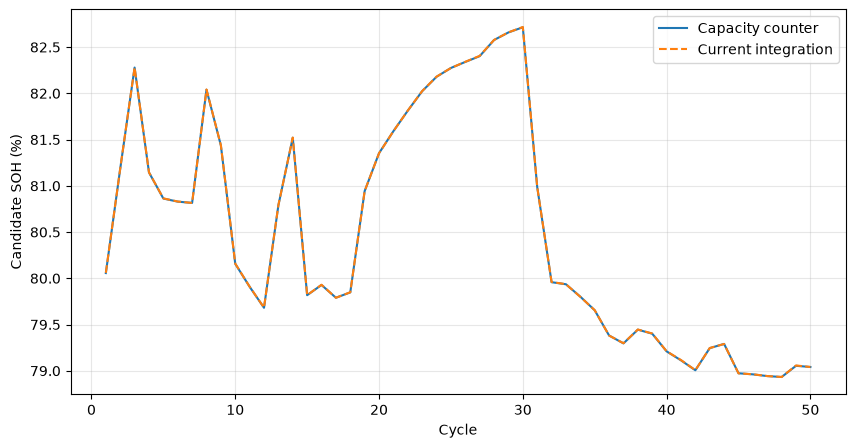

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 5))

plt.plot(
    comparison["Cycle_Index"],
    comparison["soh_candidate"],
    label="Capacity counter"
)

plt.plot(
    comparison["Cycle_Index"],
    comparison["integrated_soh"],
    "--",
    label="Current integration"
)

plt.xlabel("Cycle")
plt.ylabel("Candidate SOH (%)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [15]:
import numpy as np

error = np.abs(
    comparison["soh_candidate"] -
    comparison["integrated_soh"]
)

print("Mean difference:", error.mean(), "percentage points")
print("Maximum difference:", error.max(), "percentage points")
print("Correlation:", comparison[
    ["soh_candidate", "integrated_soh"]
].corr().iloc[0, 1])

Mean difference: 0.0012956087206552524 percentage points
Maximum difference: 0.003772969658413672 percentage points
Correlation: 0.9999995276134629


In [16]:
from pathlib import Path
import pandas as pd
import numpy as np
from tqdm.auto import tqdm

ROOT = Path(r"D:\battery_soh\CALCE-CX2\CX2_data")
OUTPUT = ROOT.parent / "cx2_cycles.csv"

files = sorted(ROOT.rglob("*.xlsx"))

print("Excel files:", len(files))

Excel files: 419


d:\battery_soh\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [17]:
records = []
errors = []

for file in tqdm(files, desc="Processing CX2 batteries"):
    battery = next(
        (p for p in file.relative_to(ROOT).parts
         if p.startswith("CX2_")),
        file.parent.name
    )

    try:
        with pd.ExcelFile(file) as book:
            for sheet in book.sheet_names:
                if not sheet.startswith("Channel"):
                    continue

                df = pd.read_excel(book, sheet_name=sheet)
                df.columns = df.columns.astype(str).str.strip()

                cols = [
                    "Cycle_Index", "Step_Index",
                    "Test_Time(s)", "Current(A)",
                    "Voltage(V)", "Discharge_Capacity(Ah)"
                ]

                if not all(c in df.columns for c in cols):
                    errors.append((file.name, sheet, "Missing columns"))
                    continue

                df = df[cols].copy()

                for col in cols:
                    df[col] = pd.to_numeric(df[col], errors="coerce")

                df = df.dropna(
                    subset=["Cycle_Index", "Step_Index",
                            "Test_Time(s)", "Current(A)", "Voltage(V)"]
                )

                for cycle, group in df.groupby("Cycle_Index", sort=False):
                    group = group.sort_values("Test_Time(s)")

                    # Integrate only contiguous discharge intervals
                    t = group["Test_Time(s)"].to_numpy()
                    i = group["Current(A)"].to_numpy()
                    steps = group["Step_Index"].to_numpy()

                    dt = np.diff(t)

                    valid = (
                        (dt > 0) &
                        (dt <= 300) &
                        (i[:-1] < -0.01) &
                        (i[1:] < -0.01) &
                        (steps[:-1] == steps[1:])
                    )

                    q = np.sum(
                        -(i[:-1][valid] + i[1:][valid])
                        * 0.5 * dt[valid] / 3600
                    )

                    discharge = group[group["Current(A)"] < -0.01]

                    if discharge.empty or q <= 0:
                        continue

                    records.append({
                        "battery": battery,
                        "file": file.name,
                        "sheet": sheet,
                        "cycle_index_local": int(cycle),
                        "start_time": str(
                            pd.to_datetime(
                                file.stat().st_mtime, unit="s"
                            )
                        ),
                        "discharge_capacity_ah": q,
                        "soh_percent_candidate": q / 1.35 * 100,
                        "start_voltage": discharge["Voltage(V)"].iloc[0],
                        "end_voltage": discharge["Voltage(V)"].iloc[-1],
                        "discharge_rows": len(discharge)
                    })

    except Exception as e:
        errors.append((file.name, str(e)))

cycles = pd.DataFrame(records)

print("Candidate cycle records:", len(cycles))
print("Errors:", len(errors))
display(cycles.head(10))

Processing CX2 batteries: 100%|██████████| 419/419 [24:36<00:00,  3.52s/it]  


Candidate cycle records: 122279
Errors: 0


,battery,file,sheet,cycle_index_local,start_time,discharge_capacity_ah,soh_percent_candidate,start_voltage,end_voltage,discharge_rows
0,CX2_16,CX2_16_10_14_11.xlsx,Channel_1-006,1,2026-10-23 04:45:39.105452061,1.080784,80.058071,4.132677,2.699861,237
1,CX2_16,CX2_16_10_14_11.xlsx,Channel_1-006,2,2026-10-23 04:45:39.105452061,1.095999,81.185090,4.135916,2.699861,240
2,CX2_16,CX2_16_10_14_11.xlsx,Channel_1-006,3,2026-10-23 04:45:39.105452061,1.110767,82.279019,4.134134,2.699861,244
3,CX2_16,CX2_16_10_14_11.xlsx,Channel_1-006,4,2026-10-23 04:45:39.105452061,1.095451,81.144537,4.134459,2.699861,240
4,CX2_16,CX2_16_10_14_11.xlsx,Channel_1-006,5,2026-10-23 04:45:39.105452061,1.091656,80.863386,4.132029,2.699861,239
5,CX2_16,CX2_16_10_14_11.xlsx,Channel_1-006,6,2026-10-23 04:45:39.105452061,1.091194,80.829181,4.133486,2.699861,239
6,CX2_16,CX2_16_10_14_11.xlsx,Channel_1-006,7,2026-10-23 04:45:39.105452061,1.090985,80.813683,4.139156,2.699861,239
7,CX2_16,CX2_16_10_14_11.xlsx,Channel_1-006,8,2026-10-23 04:45:39.105452061,1.107552,82.040880,4.135107,2.699861,243
8,CX2_16,CX2_16_10_14_11.xlsx,Channel_1-006,9,2026-10-23 04:45:39.105452061,1.099415,81.438121,4.135268,2.699861,241
9,CX2_16,CX2_16_10_14_11.xlsx,Channel_1-006,10,2026-10-23 04:45:39.105452061,1.082136,80.158202,4.130085,2.699861,237


In [18]:
print(cycles[
    ["discharge_capacity_ah", "soh_percent_candidate",
     "start_voltage", "end_voltage"]
].describe())

display(
    cycles.groupby("battery").agg(
        records=("cycle_index_local", "size"),
        median_capacity=("discharge_capacity_ah", "median"),
        min_soh=("soh_percent_candidate", "min"),
        max_soh=("soh_percent_candidate", "max"),
        median_end_voltage=("end_voltage", "median")
    ).round(3)
)

       discharge_capacity_ah  soh_percent_candidate  start_voltage  \
count          122279.000000          122279.000000  122279.000000   
mean                0.149570              11.079224       3.760781   
std                 1.102911              81.697140       0.183851   
min                 0.002823               0.209122       2.992163   
25%                 0.014064               1.041812       3.613148   
50%                 0.014066               1.041900       3.728302   
75%                 0.014068               1.042067       3.905737   
max               136.219670           10090.345944       4.200728   

         end_voltage  
count  122279.000000  
mean        3.489628  
std         0.325617  
min         1.997348  
25%         3.410899  
50%         3.546651  
75%         3.698622  
max         4.078792  


,records,median_capacity,min_soh,max_soh,median_end_voltage
battery,,,,,
CX2_16,2008,1.061,6.667,925.722,2.700
CX2_3,109459,0.014,0.209,416.481,3.572
CX2_32,374,1.170,6.111,100.500,2.700
CX2_33,1688,1.027,10.412,96.000,2.700
CX2_34,1726,1.001,34.178,100.366,2.700
CX2_35,1805,1.070,4.585,101.182,2.700
CX2_36,1961,0.956,9.193,100.866,2.700
CX2_37,1274,1.106,45.515,101.210,2.700
CX2_38,1952,0.945,0.881,100.945,2.700


In [19]:
cycles["valid_candidate"] = (
    cycles["discharge_capacity_ah"].between(0.2, 1.6) &
    cycles["end_voltage"].between(2.5, 2.9) &
    (cycles["discharge_rows"] >= 20)
)

display(
    cycles.groupby("battery")["valid_candidate"]
    .agg(["sum", "count"])
)

print("Records requiring review:",
      (~cycles["valid_candidate"]).sum())

,sum,count
battery,,
CX2_16,1998,2008
CX2_3,16,109459
CX2_32,230,374
CX2_33,1681,1688
CX2_34,1724,1726
CX2_35,1797,1805
CX2_36,1958,1961
CX2_37,1274,1274
CX2_38,1948,1952


Records requiring review: 109653


In [20]:
cycles.to_csv(OUTPUT, index=False)

print("Saved:", OUTPUT)
print("Total records:", len(cycles))
print("Provisional valid records:", cycles["valid_candidate"].sum())

Saved: D:\battery_soh\CALCE-CX2\cx2_cycles.csv
Total records: 122279
Provisional valid records: 12626
